# PRISM Homework 02 — From Colors to Regions
## Masks, Connected Components, Superpixels, and Region-Level Recoloring

**Project:** PRISM — *Perceptual Recoloring for Inclusive School Materials*  
**Recommended time:** 2–3 hours

PRISM v0.1 could recognize colors, but it had an important weakness:

> Two separate objects may have the same color.

This homework upgrades the system from **color-level reasoning** to **region-level reasoning**.

Cells marked **TODO** are intentionally incomplete.

## Learning goals

By the end, you should be able to:

1. Create and interpret a binary mask.
2. Separate disconnected objects with connected components.
3. Measure area, centroid, bounding box, and mean color.
4. Clean masks with morphology.
5. Extract contours.
6. Combine K-means with connected components.
7. Use SLIC superpixels.
8. Build simple region adjacency.
9. Compare adjacent regions under CVD simulation.
10. Recolor one region without changing all pixels of the same color.


# 0. Setup

In [ ]:
!pip -q install colorspacious

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from PIL import Image, ImageDraw
from sklearn.cluster import KMeans
from skimage import color
from skimage.segmentation import slic, mark_boundaries
from colorspacious import cspace_convert
from itertools import combinations
from IPython.display import display

np.random.seed(42)
print("Setup complete ✓")

Setup complete ✓


# 1. Practice Image

We will create a textbook-style **cell transport diagram**. Several different objects intentionally share similar green colors.

In [ ]:
def make_diagram(width=760, height=500):
    img = Image.new("RGB", (width, height), "white")
    d = ImageDraw.Draw(img)

    d.text((20, 15), "Cell Membrane Transport", fill=(20,20,20))

    # Green membrane bands
    d.rectangle((95,120,665,150), fill=(60,145,80), outline=(30,80,40), width=2)
    d.rectangle((95,330,665,360), fill=(60,145,80), outline=(30,80,40), width=2)

    # Red channel
    d.rounded_rectangle((180,155,285,325), radius=18,
                        fill=(195,60,55), outline=(110,25,20), width=4)
    d.text((205,235), "CHANNEL", fill="white")

    # Blue pump
    d.rounded_rectangle((460,155,565,325), radius=18,
                        fill=(55,120,205), outline=(25,60,120), width=4)
    d.text((490,235), "PUMP", fill="white")

    # Red particles
    for x,y in [(130,85),(170,75),(215,85),(330,80),(610,90)]:
        d.ellipse((x-11,y-11,x+11,y+11), fill=(205,55,55), outline=(120,25,25), width=2)

    # Green particles
    for x,y in [(340,405),(385,420),(430,405),(585,415),(630,405)]:
        d.ellipse((x-11,y-11,x+11,y+11), fill=(55,155,70), outline=(25,90,40), width=2)

    # Green legend: same general color, different meaning
    d.rectangle((15,375,125,465), fill=(55,155,70), outline=(25,90,40), width=3)
    d.text((38,400), "GREEN", fill="white")
    d.text((27,425), "molecule", fill="white")

    # Red legend
    d.rectangle((635,375,745,465), fill=(205,55,55), outline=(120,25,25), width=3)
    d.text((666,400), "RED", fill="white")
    d.text((651,425), "molecule", fill="white")

    # Red and green arrows
    d.line((230,95,230,155), fill=(205,55,55), width=9)
    d.polygon([(230,155),(217,135),(243,135)], fill=(205,55,55))

    d.line((515,325,515,392), fill=(55,155,70), width=9)
    d.polygon([(515,392),(502,372),(528,372)], fill=(55,155,70))

    d.text((310,185), "OUTSIDE", fill=(35,35,35))
    d.text((325,285), "INSIDE", fill=(35,35,35))

    # Small noise dots
    rng = np.random.default_rng(42)
    for _ in range(35):
        x = int(rng.integers(20, width-20))
        y = int(rng.integers(40, height-20))
        c = [(55,155,70),(205,55,55),(55,120,205)][int(rng.integers(0,3))]
        r = int(rng.integers(1,4))
        d.ellipse((x-r,y-r,x+r,y+r), fill=c)

    return np.array(img)

image = make_diagram()

plt.figure(figsize=(13,8))
plt.imshow(image)
plt.axis("off")
plt.show()

print("Image shape:", image.shape)

## Or using a actual picture

https://formaclorimerbooks.ca/wp-content/uploads/sites/4/2026/05/9781459420571-scaled.jpg

Saving 9781459420571-scaled.jpg to 9781459420571-scaled.jpg


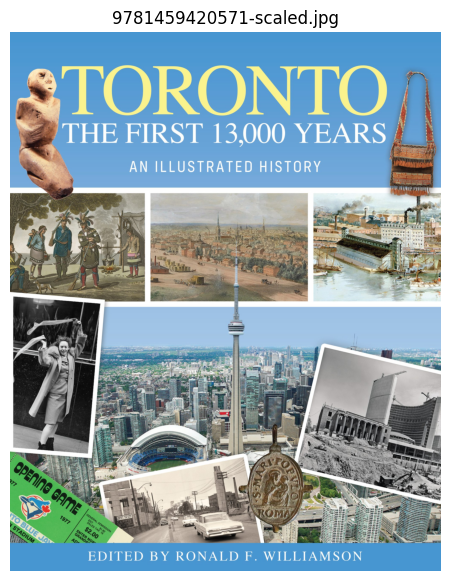

Shape: (2560, 2043, 3)


In [ ]:
try:
    from google.colab import files

    uploaded = files.upload()

    if uploaded:
        filename = next(iter(uploaded))
        image = np.array(Image.open(filename).convert("RGB"))

        plt.figure(figsize=(12,7))
        plt.imshow(image)
        plt.axis("off")
        plt.title(filename)
        plt.show()

        print("Shape:", image.shape)

except ImportError:
    print("Upload helper is designed for Google Colab.")

## 🧠 Predict First

1. Which objects share similar greens?
2. Do they have the same meaning?
3. What would go wrong if PRISM changed **all green pixels** to purple?

**Your answer:**

>

# 2. Binary Masks

A binary mask contains only:


$$0 = 	\text{background},\qquad 1 = 	\text{target}$$


We will detect green pixels with a simple rule.

In [ ]:
# TODO 1: extract RGB channels
R = image[:,:,0]
G = image[:,:,1]
B = image[:,:,2]

if R is None or G is None or B is None:
    print("TODO: extract the three channels.")
else:
    assert R.shape == image.shape[:2]
    assert G.shape == image.shape[:2]
    assert B.shape == image.shape[:2]
    print("✓ Channels extracted")

✓ Channels extracted


Hint: Using the `&` to combine all three logics together

In [ ]:
print(green_mask)

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]


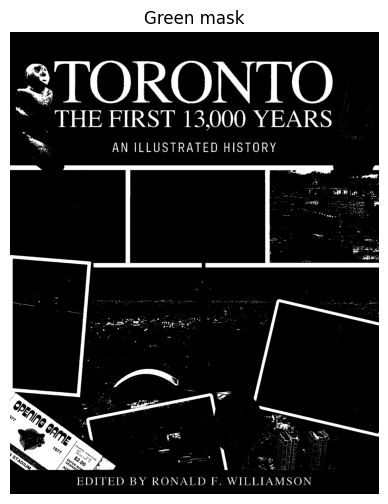

Green pixels: 528894


In [ ]:
# TODO 2: create a green mask using:
# G > 100
# G > R + 20
# G > B + 20

green_mask =(G>100) & (G>R+20) & (G>B+20)

if green_mask is None:
    print("TODO: build green_mask.")
else:
    plt.figure(figsize=(12,6))
    plt.imshow(green_mask, cmap="gray")
    plt.axis("off")
    plt.title("Green mask")
    plt.show()

    print("Green pixels:", int(green_mask.sum()))

### Investigator Question

Does the green mask contain one object or many?

Why does the mask still not tell us automatically which pixels form separate objects?

**Your answer:**

>

In [ ]:
# TODO 3: keep only green pixels and set everything else to black
# Hint: using ~ sign to negate the logic, and such assign those not in the mask to (0,0,0) color

if green_mask is not None:
    masked = image.copy()

    # YOUR CODE HERE

    plt.figure(figsize=(12,6))
    plt.imshow(masked)
    plt.axis("off")
    plt.title("Masked image")
    plt.show()

# 3. Connected Components

Connected-components analysis assigns different labels to disconnected foreground regions.

With 8-connectivity, horizontal, vertical, and diagonal touching can count as connected.

https://www.geeksforgeeks.org/machine-learning/python-opencv-connected-component-labeling-and-analysis/

In [ ]:
# TODO 4: run connectedComponentsWithStats using connectivity=8

if green_mask is not None:
    cc_result = None

    if cc_result is None:
        print("TODO: run connected-components analysis.")
    else:
        num_labels, labels, stats, centroids = cc_result

        print("Foreground components:", num_labels - 1)

        plt.figure(figsize=(12,6))
        plt.imshow(labels, cmap="nipy_spectral")
        plt.axis("off")
        plt.title("Connected component IDs")
        plt.show()

## ✏️ Region property table

For each component, extract:

- area,
- bounding box,
- centroid.

In [ ]:
if 'num_labels' in globals():
    rows = []

    for region_id in range(1, num_labels):
        x = stats[region_id, cv2.CC_STAT_LEFT]
        y = stats[region_id, cv2.CC_STAT_TOP]
        w = stats[region_id, cv2.CC_STAT_WIDTH]
        h = stats[region_id, cv2.CC_STAT_HEIGHT]
        area = stats[region_id, cv2.CC_STAT_AREA]

        # TODO 5 from the "centriods" variable above
        cx = None
        cy = None

        if cx is None or cy is None:
            continue

        rows.append({
            "id": region_id,
            "area": area,
            "x": x,
            "y": y,
            "width": w,
            "height": h,
            "centroid_x": cx,
            "centroid_y": cy
        })

    if rows:
        component_df = pd.DataFrame(rows)
        display(component_df.sort_values("area", ascending=False))
    else:
        print("TODO: extract the centroids.")

## 🔍 Investigator Question

Which components are probably:

- membrane bands?
- molecules?
- legend?
- noise?

Why is **area** useful, and why can area alone never tell us an object's meaning?

**Your answer:**

>

# 4. Filter Noise by Region Area

In [ ]:
# TODO 6: try 20, 100, and 500
MIN_AREA = None

if 'num_labels' in globals() and MIN_AREA is not None:
    filtered_mask = np.zeros_like(green_mask, dtype=bool)
    kept = []

    for region_id in range(1, num_labels):
        area = stats[region_id, cv2.CC_STAT_AREA]

        if area >= MIN_AREA:
            filtered_mask[labels == region_id] = True
            kept.append(region_id)

    print("Components kept:", len(kept))

    plt.figure(figsize=(12,6))
    plt.imshow(filtered_mask, cmap="gray")
    plt.axis("off")
    plt.title(f"Filtered mask: MIN_AREA={MIN_AREA}")
    plt.show()

## 🧪 Experiment 1 — Area Threshold

Run the previous cell three times.

| MIN_AREA | Components kept | Noise remaining? | Useful object removed? |
|---:|---:|---|---|
| 20 | | | |
| 100 | | | |
| 500 | | | |

Which threshold would you choose, and why?

>

# 5. Morphological Cleanup

In [ ]:
# TODO 7: apply morphological opening with a 3x3 kernel

if green_mask is not None:
    kernel = np.ones((3,3), np.uint8)

    opened = cv2.morphologyEx(
        green_mask.astype(np.uint8),
        cv2.MORPH_OPEN,
        kernel
    ).astype(bool)

    if opened is None:
        print("TODO: use cv2.morphologyEx(..., cv2.MORPH_OPEN, ...)")
    else:
        fig, axes = plt.subplots(1,2,figsize=(14,6))
        axes[0].imshow(green_mask, cmap="gray")
        axes[0].set_title("Before")
        axes[0].axis("off")

        axes[1].imshow(opened, cmap="gray")
        axes[1].set_title("After opening")
        axes[1].axis("off")
        plt.show()

### Investigator Question

What disappeared after opening?

Could a stronger morphological operation accidentally damage:

- arrows,
- graph lines,
- text strokes?

Explain.

>

# 6. Contours (Optional)

https://www.geeksforgeeks.org/python/find-and-draw-contours-using-opencv-python/

In [ ]:
# TODO 8: find external contours from filtered_mask

if 'filtered_mask' in globals():
    contour_result = cv2.findContours(
        filtered_mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if contour_result is None:
        print("TODO: use cv2.findContours.")
    else:
        contours, hierarchy = contour_result
        contour_img = image.copy()

        cv2.drawContours(contour_img, contours, -1, (0,0,0), 4)

        plt.figure(figsize=(12,6))
        plt.imshow(contour_img)
        plt.axis("off")
        plt.title("Detected boundaries")
        plt.show()

        print("Contours:", len(contours))

### Thinking Question

Suppose two neighboring colors are difficult to distinguish under deuteranopia.

Could a thick black outline improve accessibility **without changing the colors**?

Why is this important for PRISM?

>

# 7. Generalize: K-Means + Connected Components

In [ ]:
H, W, _ = image.shape
X = image.reshape(-1,3)

# TODO 9
K = None
model = None
pixel_clusters = None

if K is None or model is None or pixel_clusters is None:
    print("TODO: fit K-means, suggested K=7.")
else:
    cluster_img = pixel_clusters.reshape(H,W)
    palette = np.clip(model.cluster_centers_,0,255).astype(np.uint8)

    print("Palette:")
    print(palette)

    plt.figure(figsize=(12,6))
    plt.imshow(cluster_img, cmap="tab20")
    plt.axis("off")
    plt.title("K-means cluster labels")
    plt.show()

## Main Coding Exercise — Split each K-means cluster spatially (NOW LETS PUT EVERYTHING TOGETHER!!)

For every K-means cluster:

1. create a binary mask;
2. run connected components;
3. remove tiny components;
4. compute region mean color;
5. compute region centroid;
6. save the region mask.

In [ ]:
if 'cluster_img' in globals():
    MIN_REGION_AREA = 120
    regions = []
    next_id = 0

    for cluster_id in range(K):
        cluster_mask = (cluster_img == cluster_id).astype(np.uint8)

        # TODO 10a: connected components
        cc = None

        if cc is None:
            continue

        n_cc, cc_labels, cc_stats, cc_centroids = cc

        for cc_id in range(1, n_cc):
            area = cc_stats[cc_id, cv2.CC_STAT_AREA]

            # TODO 10b: skip if area is too small
            # YOUR CODE HERE

            mask = (cc_labels == cc_id)

            # TODO 10c: region pixels and mean RGB
            region_pixels = None
            mean_rgb = None

            # TODO 10d: centroid
            cx = None
            cy = None

            if region_pixels is None or mean_rgb is None or cx is None or cy is None:
                continue

            regions.append({
                "region_id": next_id,
                "cluster_id": cluster_id,
                "area": int(area),
                "centroid_x": float(cx),
                "centroid_y": float(cy),
                "mean_rgb": mean_rgb,
                "mask": mask
            })

            next_id += 1

    if not regions:
        print("TODO: complete the region extraction code.")
    else:
        region_df = pd.DataFrame([{
            "region_id": r["region_id"],
            "cluster_id": r["cluster_id"],
            "area": r["area"],
            "centroid_x": r["centroid_x"],
            "centroid_y": r["centroid_y"],
            "mean_r": r["mean_rgb"][0],
            "mean_g": r["mean_rgb"][1],
            "mean_b": r["mean_rgb"][2],
        } for r in regions])

        print("Retained regions:", len(regions))
        display(region_df.sort_values("area", ascending=False))

## 🔍 Investigator Question

Find one K-means cluster that produced several connected regions.

Why is this useful?

Complete:

> K-means understands __________ similarity, while connected components add __________ information.

>

In [ ]:
# Visualize unique region IDs

if 'regions' in globals() and regions:
    region_label_img = np.zeros((H,W), dtype=int)

    for r in regions:
        region_label_img[r["mask"]] = r["region_id"] + 1

    plt.figure(figsize=(13,7))
    plt.imshow(region_label_img, cmap="nipy_spectral")
    plt.axis("off")
    plt.title("PRISM v0.2: independent region IDs")
    plt.show()

# 8. SLIC Superpixels

SLIC groups pixels using both appearance and location.

Try different numbers of superpixels.

https://pyimagesearch.com/2014/07/28/a-slic-superpixel-tutorial-using-python/

Actual superpixels: 177


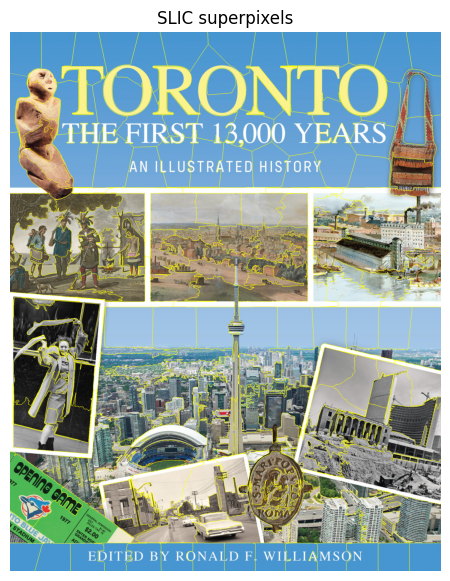

In [ ]:
# TODO 11: run SLIC
# Suggested starting parameters:
# n_segments=120, compactness=10, start_label=0

slic_labels = slic(
    image,
    n_segments=250,
    start_label=0,
    sigma=2
)

if slic_labels is None:
    print("TODO: run slic(...).")
else:
    print("Actual superpixels:", len(np.unique(slic_labels)))

    plt.figure(figsize=(13,7))
    plt.imshow(mark_boundaries(image/255.0, slic_labels))
    plt.axis("off")
    plt.title("SLIC superpixels")
    plt.show()

## 🧪 Experiment 2 — Superpixel Count

Try:

- 50
- 120
- 250
- 500

| Requested | Observation | Too coarse / reasonable / too fine? |
|---:|---|---|
| 50 | | |
| 120 | | |
| 250 | | |
| 500 | | |

Which setting seems most useful for this diagram?

>

### Compare K-means and SLIC

Which is better for:

1. extracting dominant colors?
2. separating distant objects with the same color?
3. understanding the word "membrane" or "protein"?

Explain.

>

# 9. Region Adjacency

Two regions are especially important to compare when they touch.

We create an edge:

\[
(i,j)
\]

Hint: for horizontal, it cannot have left == right, left = 0 or right = 0
Similar for vertical

whenever two region IDs meet horizontally or vertically.

In [ ]:
# TODO 12: find adjacency

if 'region_label_img' in globals():
    adjacency = set()

    left = region_label_img[:, :-1]
    right = region_label_img[:, 1:]
    top = region_label_img[:-1, :]
    bottom = region_label_img[1:, :]

    horizontal_valid = None
    vertical_valid = None

    if horizontal_valid is None or vertical_valid is None:
        print("TODO: find pixels where neighboring labels differ and both are nonzero.")
    else:
        for a,b in zip(left[horizontal_valid], right[horizontal_valid]):
            adjacency.add(tuple(sorted((int(a-1), int(b-1)))))

        for a,b in zip(top[vertical_valid], bottom[vertical_valid]):
            adjacency.add(tuple(sorted((int(a-1), int(b-1)))))

        adjacency = sorted(adjacency)

        print("Adjacency edges:", len(adjacency))
        print(adjacency[:20])

### Thinking Question

If there are 15 regions, all-pairs comparison requires:

$$\frac{15(14)}{2}=105$$

comparisons.

If only 18 pairs are adjacent, why might those 18 relationships be more meaningful for recoloring?

>

# 10. Region-Level CVD Analysis

In [ ]:
def simulate_colors(rgb_colors, cvd_type):
    rgb = np.asarray(rgb_colors, dtype=float) / 255.0
    tiny = rgb.reshape(1, len(rgb), 3)

    cvd_space = {
        "name": "sRGB1+CVD",
        "cvd_type": cvd_type,
        "severity": 100
    }

    sim = cspace_convert(tiny, cvd_space, "sRGB1")
    sim = np.clip(sim,0,1)
    return (sim.reshape(len(rgb),3)*255).astype(np.uint8)

def rgb_to_lab(rgb):
    rgb = np.asarray(rgb,dtype=float)/255.0
    return color.rgb2lab(rgb.reshape(1,1,3))[0,0]

def delta_e(rgb1,rgb2):
    lab1 = rgb_to_lab(rgb1).reshape(1,1,3)
    lab2 = rgb_to_lab(rgb2).reshape(1,1,3)
    return float(color.deltaE_ciede2000(lab1,lab2)[0,0])

Hint: comming from the variable `regions` where the mean_region column

In [ ]:
# TODO 13: make an (N_regions,3) array of mean RGB colors

if 'regions' in globals() and regions:
    region_colors = None

    if region_colors is None:
        print("TODO: build region_colors.")
    else:
        assert region_colors.shape == (len(regions),3)
        print("✓ Region colors:", region_colors.shape)

the `delta_e` function https://www.colour-science.org/api/0.3.3/html/colour.difference.delta_e.html

In [ ]:
# TODO 14: calculate ΔE for adjacent regions under normal + 3 CVD simulations

if 'region_colors' in globals() and 'adjacency' in globals():
    protan = simulate_colors(region_colors, "protanomaly")
    deutan = simulate_colors(region_colors, "deuteranomaly")
    tritan = simulate_colors(region_colors, "tritanomaly")

    rows = []

    for i,j in adjacency:
        normal_d = None
        protan_d = None
        deutan_d = None
        tritan_d = None

        if None in [normal_d,protan_d,deutan_d,tritan_d]:
            continue

        rows.append({
            "region_i": i,
            "region_j": j,
            "normal_dE": normal_d,
            "protan_dE": protan_d,
            "deutan_dE": deutan_d,
            "tritan_dE": tritan_d,
        })

    if not rows:
        print("TODO: complete the four distance calculations.")
    else:
        edge_df = pd.DataFrame(rows)
        edge_df["protan_ratio"] = edge_df["protan_dE"]/edge_df["normal_dE"]
        edge_df["deutan_ratio"] = edge_df["deutan_dE"]/edge_df["normal_dE"]
        edge_df["tritan_ratio"] = edge_df["tritan_dE"]/edge_df["normal_dE"]

        display(edge_df.sort_values("deutan_ratio").round(3))

## 🔍 Investigator Question

1. Which adjacent pair loses the most separation under deuteranopia?
2. Is the same pair worst under protanopia?
3. What happens under tritanopia?
4. Why is this more informative than simply comparing the global K-means palette?

>

# 11. Selective Region Recoloring

In [ ]:
# TODO 15: choose one region and recolor ONLY its mask

if 'regions' in globals() and regions:
    TARGET_REGION = None
    NEW_COLOR = np.array([130,70,190],dtype=np.uint8)

    if TARGET_REGION is None:
        print("TODO: choose TARGET_REGION.")
    else:
        result_img = image.copy()
        target = next(r for r in regions if r["region_id"] == TARGET_REGION)

        result_img[target["mask"]] = NEW_COLOR

        fig,axes = plt.subplots(1,2,figsize=(15,6))
        axes[0].imshow(image)
        axes[0].set_title("Original")
        axes[0].axis("off")

        axes[1].imshow(result_img)
        axes[1].set_title(f"Only region {TARGET_REGION} recolored")
        axes[1].axis("off")
        plt.show()

## 🔍 Final PRISM Comparison

### v0.1
Recolors a **color cluster**.

### v0.2
Recolors a **specific spatial region**.

Answer:

1. Why is v0.2 more precise?
2. What does v0.2 still not know?
3. What would an AI system need to know to say: "this region is a membrane protein"?

>

# 12. Design a Science-Fair Experiment

Compare:

- **Method A:** K-means global recoloring
- **Method B:** K-means + connected-components recoloring
- **Method C:** SLIC-based region recoloring

Fill in:

### Research question
>

### Independent variable
>

### Dependent variables
>

### Hypothesis
>

### One possible quantitative metric
>

# Submission Checklist

- [ ] Created RGB mask
- [ ] Applied a mask
- [ ] Ran connected components
- [ ] Measured region properties
- [ ] Tested area thresholds
- [ ] Applied morphology
- [ ] Extracted contours
- [ ] Combined K-means + connected components
- [ ] Visualized independent regions
- [ ] Tested SLIC
- [ ] Built adjacency
- [ ] Calculated region-level CVD distances
- [ ] Recolored one region selectively
- [ ] Designed a baseline comparison experiment
- [ ] Answered conceptual questions

---

## Next step

PRISM v0.2 can answer:

> **Where are the separate regions?**

But it still cannot answer:

> **What does each region mean?**

That limitation motivates **semantic segmentation, instance segmentation, pretrained vision models, and SAM**.